In [124]:
from sklearn.datasets import load_digits
X, y = load_digits(return_X_y=True)
print(X.shape, y.shape)
X_train, X_test, y_train, y_test = X[:1400], X[1400:], y[:1400], y[1400:]

(1797, 64) (1797,)


In [125]:
y_train[:20]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [126]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression()

n_labeled = 50
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])
log_reg.score(X_test, y_test)

0.7581863979848866

In [127]:
log_reg_full = LogisticRegression(tol=1e-3)
log_reg_full.fit(X_train, y_train)
log_reg_full.score(X_test, y_test)

0.9118387909319899

In [128]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=n_labeled)
X_digit_dist = kmeans.fit_transform(X_train)
print(X_digit_dist.shape)

(1400, 50)


In [129]:
representative_digit_idx = X_digit_dist.argmin(axis=0)
X_representative = X_train[representative_digit_idx]

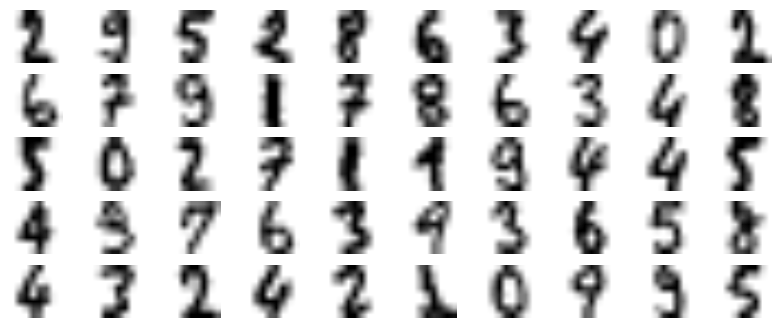

In [130]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 4))
for i in range(n_labeled):
    plt.subplot(n_labeled//10, 10, i + 1)
    plt.imshow(X_representative[i].reshape(8, 8), cmap='gray_r', interpolation='bilinear')
    plt.axis('off')
plt.show()

In [131]:
y_representative = y_train[representative_digit_idx]
for i in range(n_labeled//10):
    print(y_representative[i*10:(i+1)*10])
    

[2 9 5 2 8 6 3 4 0 2]
[6 7 9 1 7 8 6 3 4 8]
[5 0 2 7 1 1 9 4 4 5]
[4 9 7 6 3 9 3 6 5 8]
[4 3 2 4 2 1 0 9 9 5]


In [132]:
log_reg_representative = LogisticRegression(tol=1e-3)
log_reg_representative.fit(X_representative, y_representative)
log_reg_representative.score(X_test, y_test)

0.8312342569269522

In [133]:
import numpy as np
y_train_propagated = np.empty(X_train.shape[0], dtype=int)
for i in range(n_labeled):
    y_train_propagated[kmeans.labels_ == i] = y_representative[i]

In [134]:
log_reg_propagated = LogisticRegression(tol=1e-3)
log_reg_propagated.fit(X_train, y_train_propagated)
log_reg_propagated.score(X_test, y_test)

0.8841309823677582

In [135]:
print((y_train_propagated == y_train).mean())

0.9507142857142857


In [136]:
percentil_closest = 80

X_cluster_dist = X_digit_dist[np.arange(X_digit_dist.shape[0]), kmeans.labels_]
partially_propagated = np.ones(X_train.shape[0], dtype=int)* -1
for i in range(n_labeled):
    in_cluster = kmeans.labels_ == i
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_distance = np.percentile(cluster_dist, percentil_closest)
    above_cutoff = X_cluster_dist > cutoff_distance
    X_cluster_dist[in_cluster & above_cutoff] = -1
partially_propagated = X_cluster_dist != -1
X_partially_propagated = X_train[partially_propagated]
y_partially_propagated = y_train_propagated[partially_propagated]
print(len(y_partially_propagated), len(y_train))
print((y_partially_propagated == y_train[partially_propagated]).mean())

1111 1400
0.9612961296129613


In [137]:
log_reg_partially_propagated = LogisticRegression(tol=1e-3)
log_reg_partially_propagated.fit(X_partially_propagated, y_partially_propagated)
log_reg_partially_propagated.score(X_test, y_test)

0.8564231738035264